# Upload data
- select and upload train_FD001.txt, test_FD001.txt, RUL_FD001.txt

In [1]:
# Uploading data
from google.colab import files
files.upload()   # select train_FD001.txt, test_FD001.txt, RUL_FD001.txt

Saving RUL_FD001.txt to RUL_FD001.txt
Saving test_FD001.txt to test_FD001.txt
Saving train_FD001.txt to train_FD001.txt


{'RUL_FD001.txt': b'112 \n98 \n69 \n82 \n91 \n93 \n91 \n95 \n111 \n96 \n97 \n124 \n95 \n107 \n83 \n84 \n50 \n28 \n87 \n16 \n57 \n111 \n113 \n20 \n145 \n119 \n66 \n97 \n90 \n115 \n8 \n48 \n106 \n7 \n11 \n19 \n21 \n50 \n142 \n28 \n18 \n10 \n59 \n109 \n114 \n47 \n135 \n92 \n21 \n79 \n114 \n29 \n26 \n97 \n137 \n15 \n103 \n37 \n114 \n100 \n21 \n54 \n72 \n28 \n128 \n14 \n77 \n8 \n121 \n94 \n118 \n50 \n131 \n126 \n113 \n10 \n34 \n107 \n63 \n90 \n8 \n9 \n137 \n58 \n118 \n89 \n116 \n115 \n136 \n28 \n38 \n20 \n85 \n55 \n128 \n137 \n82 \n59 \n117 \n20 \n',
 'test_FD001.txt': b'1 1 0.0023 0.0003 100.0 518.67 643.02 1585.29 1398.21 14.62 21.61 553.90 2388.04 9050.17 1.30 47.20 521.72 2388.03 8125.55 8.4052 0.03 392 2388 100.00 38.86 23.3735  \n1 2 -0.0027 -0.0003 100.0 518.67 641.71 1588.45 1395.42 14.62 21.61 554.85 2388.01 9054.42 1.30 47.50 522.16 2388.06 8139.62 8.3803 0.03 393 2388 100.00 39.02 23.3916  \n1 3 0.0003 0.0001 100.0 518.67 642.46 1586.94 1401.34 14.62 21.61 554.11 2388.05 9056.96 

# CMAPSS FD001 RUL Prediction - Data Prep

**Imports**
- Load pandas, numpy, time, torch, sklearn tools (scaler, RF, Ridge).

**Load data**
- Define column names: unit, cycle, 3 settings, 21 sensors.
- Read train_FD001.txt, test_FD001.txt, RUL_FD001.txt.

**Feature selection**
- Keep only useful sensors: s2,s3,s4,s7-9,s11-15,s17,s20,s21.
- CAP=125 (RUL cap), W=30 (window size).

**RUL labels + scaling**
- Compute RUL per unit = max_cycle - current_cycle, clip at 125.
- Fit MinMaxScaler on train features, transform train + test.

**Window function**
- For each unit, slide windows of length 30.
- X = sensor sequences, y = RUL at end of window, u = unit id.

**Train / val / test split**
- Create windows on train → X, y, u.
- Randomly pick 20 units for validation.
- Split into Xtr/ytr and Xv/yv.
- For test: take last 30 cycles of each unit → Xte.
- yte = true RUL from file.
- Print shapes.

In [2]:
import pandas as pd, numpy as np, time, torch, torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

# Column names
cols = ["unit","cycle"]+[f"set{i}" for i in range(1,4)]+[f"s{i}" for i in range(1,22)]

# Load data
tr = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None, names=cols)
te = pd.read_csv("test_FD001.txt",  sep=r"\s+", header=None, names=cols)
rt = pd.read_csv("RUL_FD001.txt", header=None, names=["rul"])

# Selected sensors
feats = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]
CAP, W = 125, 30  # RUL cap, window size

# Compute RUL (capped)
tr["rul"] = (tr.groupby("unit").cycle.transform("max") - tr.cycle).clip(upper=CAP)

# Scale features
sc = MinMaxScaler().fit(tr[feats])
tr[feats] = sc.transform(tr[feats]); te[feats] = sc.transform(te[feats])

# Create sliding windows
def wins(df):
    X, y, u = [], [], []
    for k, g in df.groupby("unit"):
        d, r = g[feats].values, g["rul"].values
        for e in range(W, len(g)+1):
            X.append(d[e-W:e]); y.append(r[e-1]); u.append(k)
    return np.array(X), np.array(y), np.array(u)

X, y, u = wins(tr)

# Validation units
val = np.random.RandomState(0).choice(np.arange(1,101), 20, replace=False)
mv = np.isin(u, val)
Xtr, ytr, Xv, yv = X[~mv], y[~mv], X[mv], y[mv]

# Test windows (last W cycles)
Xte = np.array([g[feats].values[-W:] for _, g in te.groupby("unit")])
yte = rt.rul.values
print(X.shape, Xtr.shape, Xv.shape, Xte.shape)

(17731, 30, 14) (14115, 30, 14) (3616, 30, 14) (100, 30, 14)


# Models + Metrics

**Metrics**
- rmse: Root Mean Squared Error
- nasa: NASA scoring function (penalizes late predictions more)

**Helpers**
- results list + preds dict to store scores and predictions
- add(): clips preds, computes metrics, stores them
- flat: flattens 3D windows → 2D for classical models

**Ridge**
- Train Ridge regression on flattened windows
- Predict val + test, record time + metrics

**RandomForest**
- Train RF (100 trees, depth 14, subsample every 3rd row for speed)
- Predict val + test, record time + metrics

In [3]:
# Metrics
rmse = lambda a, b: float(np.sqrt(np.mean((a-b)**2)))
def nasa(p, t):
    d = p - t
    return float(np.sum(np.where(d < 0, np.exp(-d/13)-1, np.exp(d/10)-1)))

results, preds = [], {}
def add(name, pv, pt, sec):
    pt = np.clip(pt, 0, CAP); preds[name] = pt
    results.append(dict(model=name, val_rmse=rmse(pv, yv), test_rmse=rmse(pt, yte),
        test_rmse_capped=rmse(pt, np.minimum(yte, CAP)), nasa_score=nasa(pt, yte), seconds=sec))

flat = lambda a: a.reshape(len(a), -1)  # flatten windows

# Ridge
t = time.time(); m = Ridge(alpha=1.0).fit(flat(Xtr), ytr)
add("Ridge", m.predict(flat(Xv)), m.predict(flat(Xte)), time.time()-t)

# Random Forest (subsample for speed)
t = time.time()
m = RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=5,
        max_features=0.15, n_jobs=-1, random_state=0).fit(flat(Xtr)[::3], ytr[::3])
add("RandomForest", m.predict(flat(Xv)), m.predict(flat(Xte)), time.time()-t)

# Deep Learning Models (MLP + LSTM)

**Setup**
- Use GPU if available, else CPU
- T: helper to convert arrays → float32 tensors

**MLP**
- Flatten window → Linear(W*feats → 128) → ReLU → Dropout → Linear(128→64) → ReLU → Linear(64→1)

**LSTM**
- 2-layer LSTM (input=feats, hidden=64, dropout=0.2)
- Take last timestep → Linear → 1 output

**fit()**
- Train with Adam, MSE loss, batch size 256
- Early stop if val RMSE doesn't improve for 8 epochs
- Restore best weights

**pred()**
- Run model in eval mode, return numpy predictions

**Train & evaluate**
- Fit MLP and LSTM
- Predict on val + test, add scores to results
- Save results table as CSV and display


**Training details**
- Both models use the same training function, so the comparison is fair.
- Targets are scaled to 0-1 (RUL / 125). Without this, the first LSTM run got
  stuck predicting the average value for every engine (RMSE about 41).
- We train on 80 engines and check progress on 20 validation engines.
- Early stopping: training stops when the validation RMSE has not improved for
  20 epochs, and the best weights are restored.
- The validation RMSE is printed every 5 epochs so we can watch the learning.

In [4]:
# Remove old MLP/LSTM rows so rerunning this cell does not create duplicates
results = [r for r in results if r["model"] in ("Ridge", "RandomForest")]

# Use GPU if Colab has one, otherwise CPU
dev = "cuda" if torch.cuda.is_available() else "cpu"
T = lambda a: torch.tensor(a, dtype=torch.float32)   # numpy -> torch tensor

# ---------- Model 1: MLP ----------
class MLP(nn.Module):
    def __init__(s):
        super().__init__()
        s.net = nn.Sequential(
            nn.Flatten(),                      # (batch, 30, 14) -> (batch, 420)
            nn.Linear(W*len(feats), 128), nn.ReLU(),
            nn.Dropout(0.2),                   # randomly drop 20% to reduce overfitting
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1))                  # one output: the RUL
    def forward(s, x): return s.net(x).squeeze(-1)   # (batch, 1) -> (batch,)

# ---------- Model 2: LSTM ----------
class LSTM(nn.Module):
    def __init__(s, hidden=64, layers=2):
        super().__init__()
        # 2 stacked LSTM layers, each with 64 hidden units; dropout between layers
        s.lstm = nn.LSTM(len(feats), hidden, layers, batch_first=True, dropout=0.2)
        s.head = nn.Linear(hidden, 1)          # turns the final memory into one number
    def forward(s, x):
        out, _ = s.lstm(x)                     # out: (batch, 30, hidden)
        return s.head(out[:, -1]).squeeze(-1)  # use only the last flight's output

# ---------- Training loop (shared by both models) ----------
def fit(model, epochs=150, lr=1e-3, bs=128, patience=20, min_epochs=30, seed=0):
    torch.manual_seed(seed)                    # same seed -> repeatable results
    model = model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    # Move data to the device; targets are scaled to 0-1 (divided by the cap)
    Xt,  yt  = T(Xtr).to(dev), T(ytr/CAP).to(dev)
    Xvv, yvv = T(Xv).to(dev),  T(yv/CAP).to(dev)

    best, bad, state = 1e9, 0, None            # best val RMSE, epochs without gain, best weights
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt), device=dev)       # shuffle windows each epoch
        for i in range(0, len(Xt), bs):                  # go through data in mini-batches
            idx = perm[i:i+bs]
            opt.zero_grad()
            loss = ((model(Xt[idx]) - yt[idx])**2).mean()   # mean squared error
            loss.backward()                                  # compute gradients
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # stop huge updates
            opt.step()                                       # update weights

        # Check progress on validation engines (RMSE converted back to real flights)
        model.eval()
        with torch.no_grad():
            v = ((model(Xvv) - yvv)**2).mean().sqrt().item() * CAP
        if ep % 5 == 0: print(f"epoch {ep}  val RMSE {v:.2f}")

        # Early stopping: keep the best weights, stop if no gain for `patience` epochs
        if v < best:
            best, bad = v, 0
            state = {k: x.clone() for k, x in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience and ep >= min_epochs: break

    model.load_state_dict(state)               # go back to the best epoch
    return model

# ---------- Prediction helper ----------
def pred(model, A):
    model.eval()
    with torch.no_grad():
        return model(T(A).to(dev)).cpu().numpy() * CAP   # scale back to real flights

# ---------- Train both, record results ----------
for name, mdl in [("MLP", MLP()), ("LSTM", LSTM())]:
    t = time.time()
    mdl = fit(mdl)
    add(name, pred(mdl, Xv), pred(mdl, Xte), time.time() - t)   # add() computes the metrics

res = pd.DataFrame(results).round(2)           # results table
res.to_csv("results.csv", index=False)         # saved for the report
res

epoch 0  val RMSE 21.09
epoch 5  val RMSE 14.10
epoch 10  val RMSE 13.29
epoch 15  val RMSE 14.54
epoch 20  val RMSE 13.21
epoch 25  val RMSE 14.87
epoch 30  val RMSE 15.45
epoch 0  val RMSE 20.93
epoch 5  val RMSE 13.16
epoch 10  val RMSE 12.61
epoch 15  val RMSE 14.26
epoch 20  val RMSE 12.51
epoch 25  val RMSE 12.48
epoch 30  val RMSE 13.33
epoch 35  val RMSE 13.43
epoch 40  val RMSE 12.39
epoch 45  val RMSE 12.44


,model,val_rmse,test_rmse,test_rmse_capped,nasa_score,seconds
0,Ridge,16.78,16.05,14.66,411.39,0.28
1,RandomForest,16.34,17.79,16.50,648.24,13.66
2,MLP,13.08,14.87,13.34,351.54,14.34
3,LSTM,12.30,14.89,13.54,358.41,18.71


# Prediction Plots

- Create side-by-side scatter plots (one per model)
- X = true RUL, Y = predicted RUL
- Red dashed line = perfect prediction
- Save figure as pred_vs_true.png

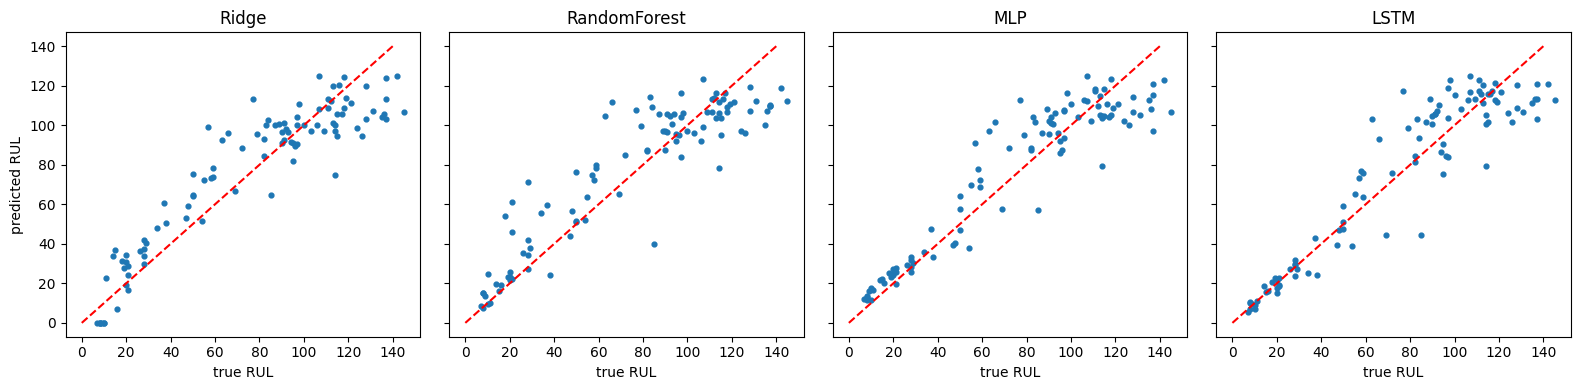

In [5]:
import matplotlib.pyplot as plt

# Scatter plots: true vs predicted RUL
fig, ax = plt.subplots(1, len(preds), figsize=(4*len(preds), 4), sharey=True)
for a, (n, p) in zip(ax, preds.items()):
    a.scatter(yte, p, s=12); a.plot([0,140],[0,140],"r--"); a.set_title(n); a.set_xlabel("true RUL")
ax[0].set_ylabel("predicted RUL"); plt.tight_layout(); plt.savefig("pred_vs_true.png", dpi=150)